In [1]:
%matplotlib inline

In [2]:
%env SIT_ROOT=/sdf/group/lcls/ds/ana
%env SIT_PSDM_DATA=/sdf/data/lcls/ds
%env CONDA_ENVS_DIRS=/sdf/group/lcls/ds/ana/sw/conda1/inst/envs
%env SIT_DATA=$CONDA_ENVS_DIRS/ana-4.0.59-py3/data:$SIT_ROOT/data/

env: SIT_ROOT=/sdf/group/lcls/ds/ana
env: SIT_PSDM_DATA=/sdf/data/lcls/ds
env: CONDA_ENVS_DIRS=/sdf/group/lcls/ds/ana/sw/conda1/inst/envs
env: SIT_DATA=$CONDA_ENVS_DIRS/ana-4.0.59-py3/data:$SIT_ROOT/data/


## Imports

In [3]:
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import sys
from pathlib import Path

sys.path.append(str(Path('..').resolve()))
from src.utilities import *

Smalldata path exists: True
Jungfrau path exists: True
epix2 path exists: True
iq path exists: True


## Jungfrau

### Loading

In [7]:
run = 146

with L10010H5Loader(run) as loader:
    iq = loader["Iq"]
    q = loader["q"]
    cc = loader["cc"]
    vcc = loader["vcc"]
    lomdiode = loader["lomdiode"]
    delay = loader["delay"]

iq_dataarray = xr.DataArray(
    coords={
        "q": q, "delay": delay, 
        "cc": ("delay", cc), "vcc": ("delay",vcc), "lomdiode": ("delay",lomdiode)
    },
    dims=("delay", "q"),
    data=iq,
    attrs={"run": run}
)
iq_dataarray = iq_dataarray.groupby_bins("q", bins=100).mean()
_q = [i.item().mid for i in iq_dataarray.q_bins]
iq_dataarray = iq_dataarray.reset_index(["q_bins"], drop=True) \
                            .rename({"q_bins": "q"}) \
                            .assign_coords(q=_q)
# Porod invariant
porod = (iq_dataarray * iq_dataarray.q**2).integrate("q")
iq_dataarray = iq_dataarray.assign_coords(porod=porod)
iq_dataarray = iq_dataarray.where(iq_dataarray.porod>10, drop=True)
iq_dataarray

<xarray.DataArray (delay: 3086, q: 100)>
array([[0.8252402 , 1.0171697 , 0.97272265, ..., 0.21047437, 0.16673896,
        0.18042694],
       [0.98673385, 1.0074402 , 1.1892368 , ..., 0.29661685, 0.31846845,
        0.30426875],
       [0.8883373 , 1.1572297 , 1.3414294 , ..., 0.2920075 , 0.26202387,
        0.01147196],
       ...,
       [0.63399786, 0.7479522 , 0.91002387, ..., 0.24716485, 0.26378506,
        0.19863011],
       [1.2699769 , 1.766304  , 1.7645104 , ..., 0.32246584, 0.37568393,
        0.17025238],
       [0.79423165, 0.9389141 , 0.91043866, ..., 0.19163042, 0.19737253,
        0.12293572]], dtype=float32)
Coordinates:
  * delay     (delay) float64 2.541 2.541 2.541 2.529 ... 2.748 2.748 2.748
    cc        (delay) float32 0.3292 0.3567 0.3917 ... 0.3261 0.5184 0.3143
    vcc       (delay) float32 0.3417 0.402 0.4282 ... 0.3368 0.5851 0.3372
    lomdiode  (delay) float32 0.7483 0.8423 0.9297 ... 0.7089 1.289 0.7256
  * q         (q) float64 1.218 1.256 1.291 1.327 ... 4.654 4.689 4.725 4.761
    porod     (delay) float64 11.82 14.03 14.07 12.24 ... 10.63 19.89 10.43
Attributes:
    run:      146

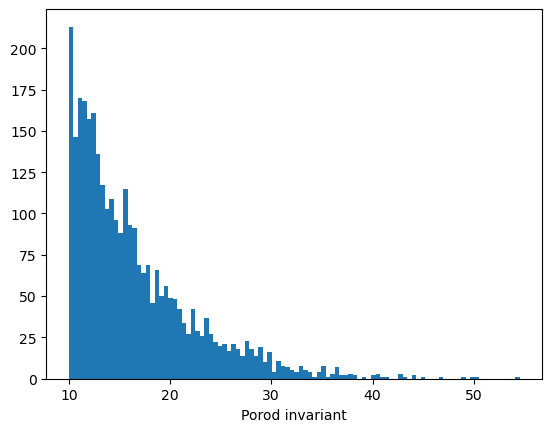

In [8]:
plt.hist(iq_dataarray.porod, bins=100)
plt.xlabel("Porod invariant")
plt.show()

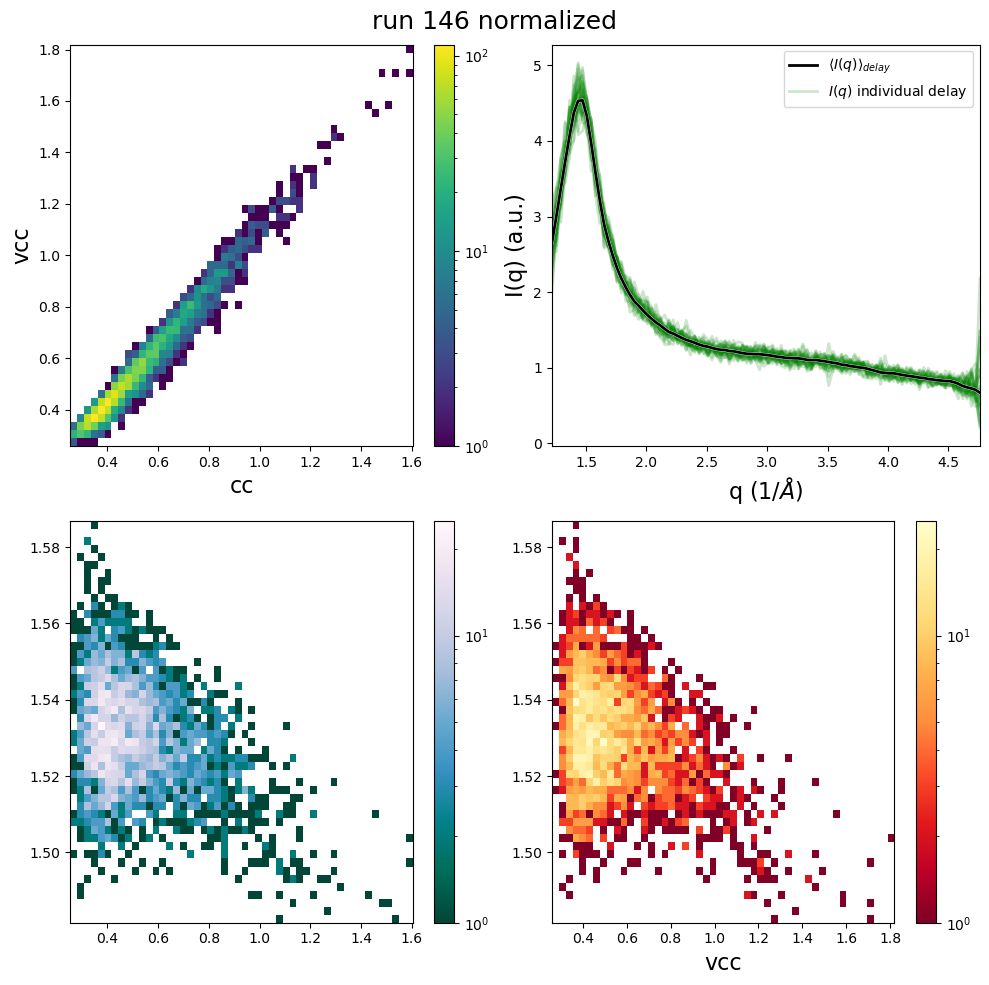

In [9]:
plotChannelsIq(iq_dataarray)

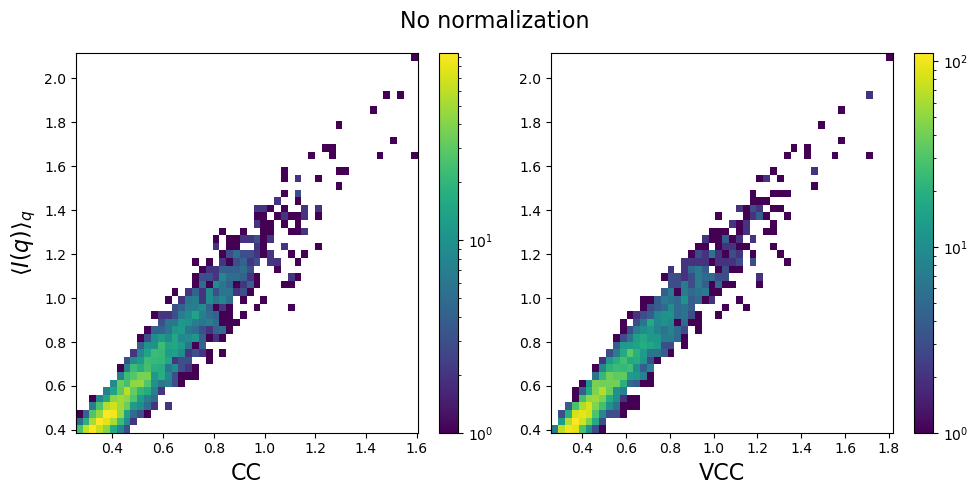

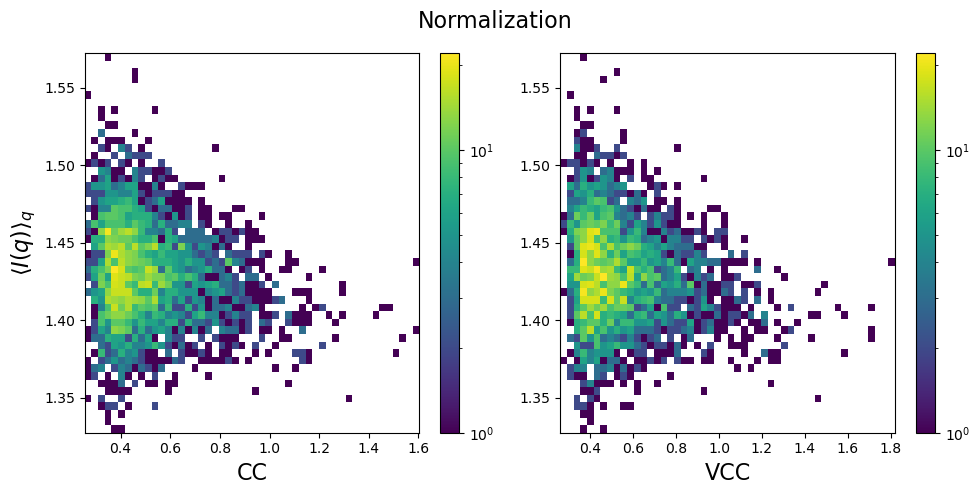

In [122]:
_temp_dataarray = iq_dataarray.where(iq_dataarray.porod > 10, drop=True)
_temp_dataarray = _temp_dataarray# / _temp_dataarray.sel(q=slice(3, 4,5)).mean("q")

fig, (ax1, ax2) = plt.subplots(1, 2, layout="tight", figsize=(10, 5))
_,_,_, h = ax1.hist2d(_temp_dataarray.cc.values, _temp_dataarray.mean("q").data, bins=50, norm=LogNorm())
ax1.set_xlabel("CC", fontsize=16)
ax1.set_ylabel(r"$\langle I(q) \rangle_{q}$", fontsize=16)
fig.colorbar(h)

_,_,_, h = ax2.hist2d(_temp_dataarray.vcc.values, _temp_dataarray.mean("q").data, bins=50, norm=LogNorm())
ax2.set_xlabel("VCC", fontsize=16)
# ax2.set_ylabel(r"$\langle I(q) \rangle_{q}$")
fig.colorbar(h)

fig.suptitle("No normalization", fontsize=16)


_temp_dataarray = _temp_dataarray / _temp_dataarray.sel(q=slice(3, 4,5)).mean("q")

fig, (ax1, ax2) = plt.subplots(1, 2, layout="tight", figsize=(10, 5))
_,_,_, h = ax1.hist2d(_temp_dataarray.cc.values, _temp_dataarray.mean("q").data, bins=50, norm=LogNorm())
ax1.set_xlabel("CC", fontsize=16)
ax1.set_ylabel(r"$\langle I(q) \rangle_{q}$", fontsize=16)
fig.colorbar(h)

_,_,_, h = ax2.hist2d(_temp_dataarray.vcc.values, _temp_dataarray.mean("q").data, bins=50, norm=LogNorm())
ax2.set_xlabel("VCC", fontsize=16)
# ax2.set_ylabel(r"$\langle I(q) \rangle_{q}$")
fig.colorbar(h)

fig.suptitle("Normalization", fontsize=16)

plt.show()

### Channel Analysis

In [ ]:
from matplotlib.patches import Rectangle

for run in range(146, 190, 10):
    with L10010H5Loader(run) as loader:
        iq = loader["Iq"]
        q = loader["q"]
        cc = loader["cc"]
        vcc = loader["vcc"]
        lomdiode = loader["lomdiode"]
        delay = loader["delay"]

    iq_dataarray = xr.DataArray(
        coords={
            "q": q, "delay": delay, 
            "cc": ("delay", cc), "vcc": ("delay",vcc), "lomdiode": ("delay",lomdiode)
        },
        dims=("delay", "q"),
        data=iq,
        attrs={"run": run}
    )
    iq_dataarray = iq_dataarray.groupby_bins("q", bins=100).mean().dropna("delay") # replaces q dimension with q_bins
    _q = [i.item().mid for i in iq_dataarray.q_bins] # get the mid value of the q bin
    iq_dataarray = iq_dataarray.reset_index(["q_bins"], drop=True) \
                                .rename({"q_bins": "q"}) \
                                .assign_coords(q=_q) # replace q_bins with the mid value of the q bin and rename as q
    # Porod invariant
    porod = (iq_dataarray * iq_dataarray.q**2).integrate("q")
    iq_dataarray = iq_dataarray.assign_coords(porod=porod)
    iq_dataarray = iq_dataarray.where(iq_dataarray.porod>10, drop=True)
    
    plotChannelsIq(iq_dataarray)
    
    del iq_dataarray, loader

### Histogram of CC/VCC

In [4]:
run = 174

with L10010H5Loader(run) as loader:
    iq = loader["Iq"]
    q = loader["q"]
    cc = loader["cc"]
    vcc = loader["vcc"]
    lomdiode = loader["lomdiode"]
    delay = loader["delay"]

iq_dataarray = xr.DataArray(
    coords={
        "q": q, "delay": delay, 
        "cc": ("delay", cc), "vcc": ("delay",vcc), "lomdiode": ("delay",lomdiode)
    },
    dims=("delay", "q"),
    data=iq,
    attrs={"run": run}
)
iq_dataarray = iq_dataarray.groupby_bins("q", bins=100).mean().dropna("delay") # replaces q dimension with q_bins
_q = [i.item().mid for i in iq_dataarray.q_bins] # get the mid value of the q bin
iq_dataarray = iq_dataarray.reset_index(["q_bins"], drop=True) \
                            .rename({"q_bins": "q"}) \
                            .assign_coords(q=_q) # replace q_bins with the mid value of the q bin and rename as q
# Porod invariant
porod = (iq_dataarray * iq_dataarray.q**2).integrate("q")
iq_dataarray = iq_dataarray.assign_coords(porod=porod)
iq_dataarray = iq_dataarray.where(iq_dataarray.porod>10, drop=True)

In [5]:
def lin_interp(x, y, i, half):
    return x[i] + (x[i+1] - x[i]) * ((half - y[i]) / (y[i+1] - y[i]))

def half_max_x(x, y):
    half = max(y)/2.0
    signs = np.sign(np.add(y, -half))
    zero_crossings = (signs[0:-2] != signs[1:-1])
    zero_crossings_i = np.where(zero_crossings)[0]
    return [lin_interp(x, y, zero_crossings_i[0], half),
            lin_interp(x, y, zero_crossings_i[1], half)]


hist_data_cc = np.histogram(iq_dataarray.cc, bins=100)
hist_data_vcc = np.histogram(iq_dataarray.vcc, bins=100)

# find the two crossing points
cc_hmx = half_max_x(hist_data_cc[1][:-1], hist_data_cc[0])
vcc_hmx = half_max_x(hist_data_vcc[1][:-1], hist_data_vcc[0])

iq_cc_hmax = iq_dataarray.where((iq_dataarray.cc<=cc_hmx[1])&(iq_dataarray.cc>=cc_hmx[0]), drop=True)
iq_vcc_hmax = iq_dataarray.where((iq_dataarray.vcc<=vcc_hmx[1])&(iq_dataarray.vcc>=vcc_hmx[0]), drop=True)

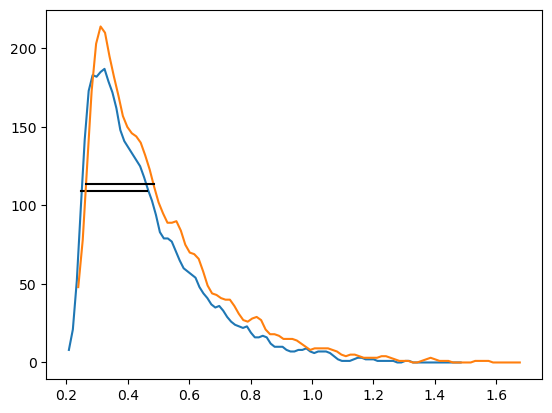

In [6]:
from scipy.ndimage import gaussian_filter

half = max(hist_data_cc[0])/2.0
plt.plot(hist_data_cc[1][:-1], gaussian_filter(hist_data_cc[0], sigma=1))
plt.plot(cc_hmx, [half, half], "k")

half = max(hist_data_vcc[0])/2.0
plt.plot(hist_data_vcc[1][:-1], gaussian_filter(hist_data_vcc[0], sigma=1))
plt.plot(vcc_hmx, [half, half], "k")
plt.show()

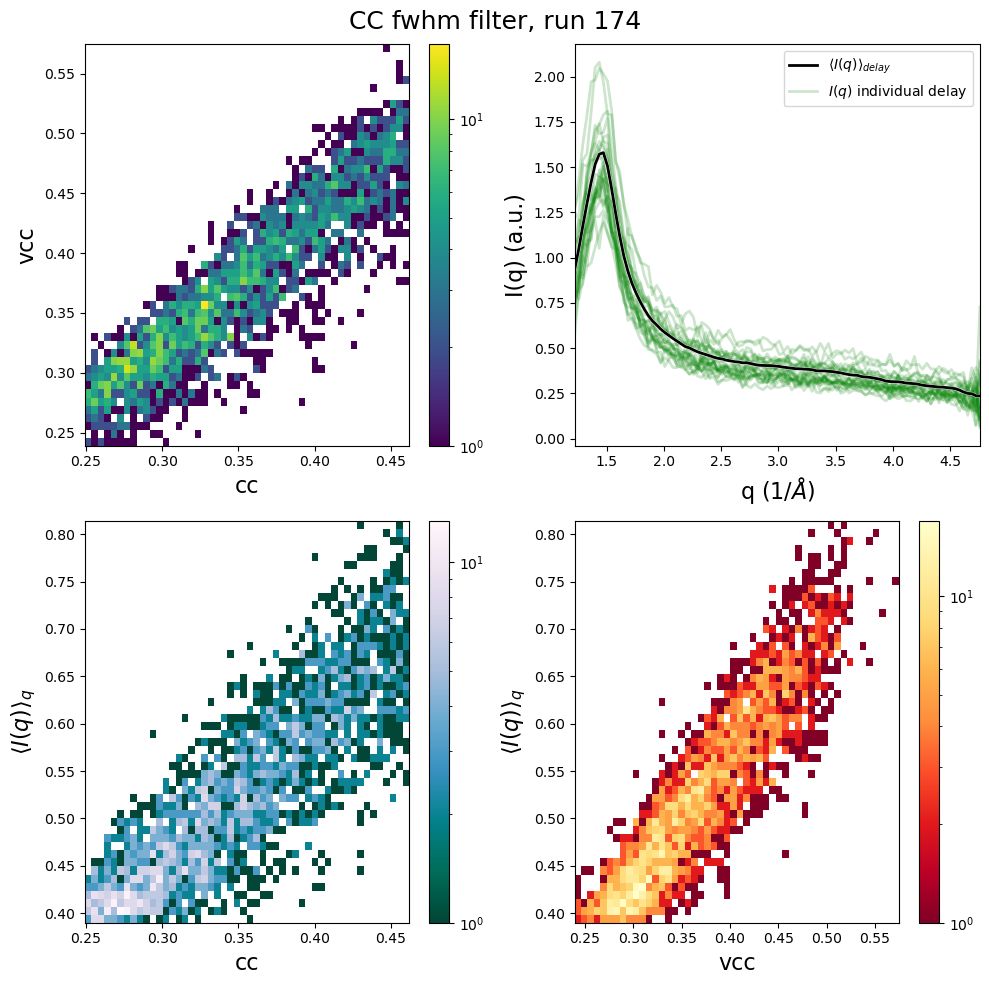

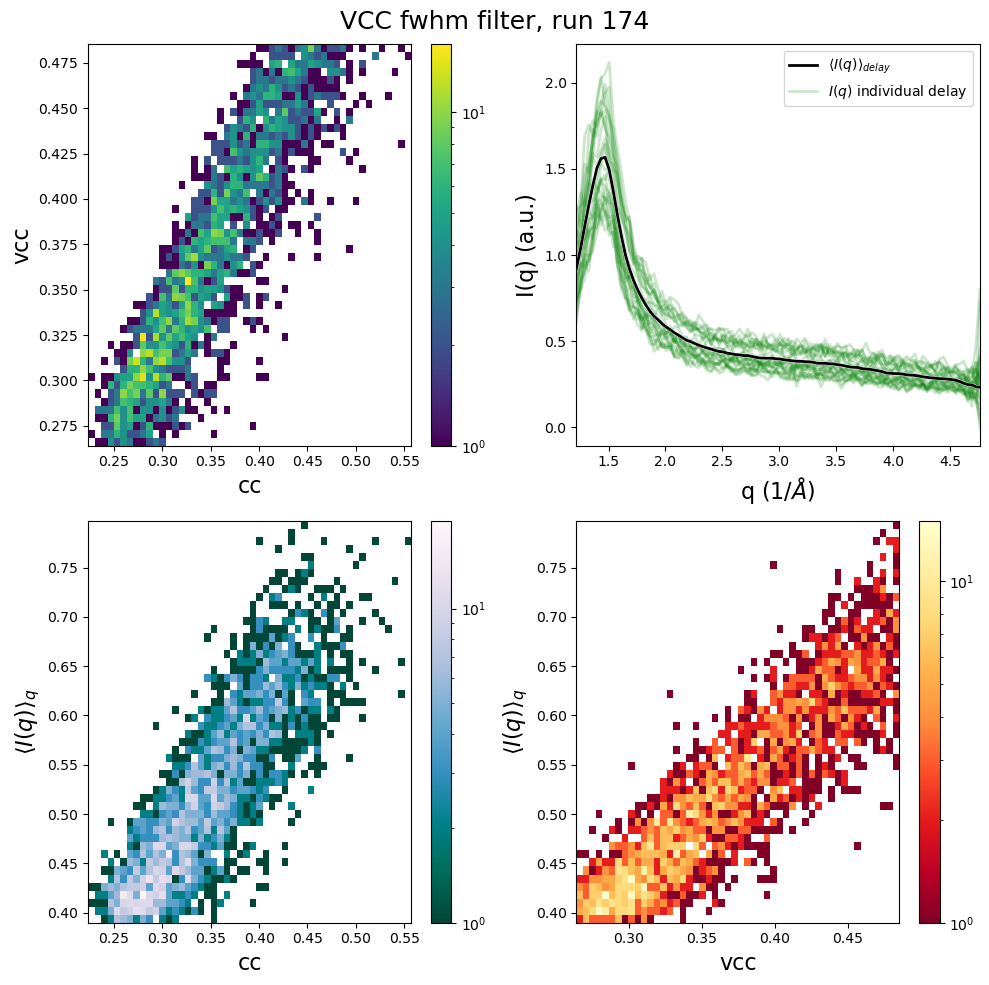

In [8]:
plotChannelsIq(iq_cc_hmax, norm=False, title=f"CC fwhm filter, run {run}")
plotChannelsIq(iq_vcc_hmax, norm=False, title=f"VCC fwhm filter, run {run}")
